In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from design.fitter import PhotonicFitter
from verification.plotting import plot_result, plot_robustness
from verification.stability import robustness

fitter = PhotonicFitter(smooth_sigma=4.0)

/Users/samuelnoger/Programms/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
initial_desig = "y_branch"
target_ratio = 0.5
# Standard Fit (no etch-bias robustness)
res_std = fitter.fit(
    target_ratio=target_ratio,
    init_mode=initial_desig,
    steps=180,
    lr=0.05,
    robust_delta=0.0,
)
plot_result(res_std)
rob_std = robustness(fitter, res_std["rho"], target_ratio=target_ratio, verbose=False)
plot_robustness(rob_std, fitter=fitter, rho_bin=res_std["rho"])

# Robust Fit (optimizes nominal, eroded -delta, and dilated +delta in final 35% of steps)
res_rob = fitter.fit(
    target_ratio=target_ratio,
    init_mode=initial_desig,
    steps=180,
    lr=0.05,
    robust_delta=0.3,
    robust_start=0.65,
)
plot_result(res_rob)
rob_rob = robustness(fitter, res_rob["rho"], target_ratio=target_ratio, verbose=False)
plot_robustness(rob_rob, fitter=fitter, rho_bin=res_rob["rho"])


Fitting [FDFD Adjoint] (50/50):  26%|██▌       | 47/180 [00:28<01:27,  1.52it/s, T1=48.3%, T2=48.3%, Tot=96.7%, beta=3.6]

In [ ]:
ratios = [0.2, 0.3, 0.5, 0.7, 0.8]
sweep_results = {}

for r in ratios:
    res = fitter.fit(
        target_ratio=r,
        init_mode=initial_desig,
        steps=180,
        lr=0.05,
        robust_delta=0.3,
        robust_start=0.65,
    )
    rob = robustness(fitter, res["rho"], target_ratio=r, biases=(-1, 0, 1), wls=(1.53, 1.55, 1.57), verbose=False)
    sweep_results[r] = {"fit": res, "rob": rob}

Fitting [FDFD Adjoint] (20/80): 100%|██████████| 180/180 [02:59<00:00,  1.00it/s, T1=16.3%, T2=80.7%, Tot=96.9%, beta=12.0]


 [FDFD Adjoint Fit in 179.8s]



Fitting [FDFD Adjoint] (30/70): 100%|██████████| 180/180 [03:02<00:00,  1.01s/it, T1=27.6%, T2=69.5%, Tot=97.0%, beta=12.0]


 [FDFD Adjoint Fit in 182.5s]



Fitting [FDFD Adjoint] (50/50): 100%|██████████| 180/180 [03:02<00:00,  1.01s/it, T1=47.9%, T2=47.9%, Tot=95.9%, beta=12.0]


 [FDFD Adjoint Fit in 182.2s]



Fitting [FDFD Adjoint] (70/30): 100%|██████████| 180/180 [03:00<00:00,  1.00s/it, T1=69.5%, T2=27.6%, Tot=97.0%, beta=12.0]


 [FDFD Adjoint Fit in 180.5s]



Fitting [FDFD Adjoint] (80/20): 100%|██████████| 180/180 [02:56<00:00,  1.02it/s, T1=80.7%, T2=16.3%, Tot=96.9%, beta=12.0]


 [FDFD Adjoint Fit in 176.4s]



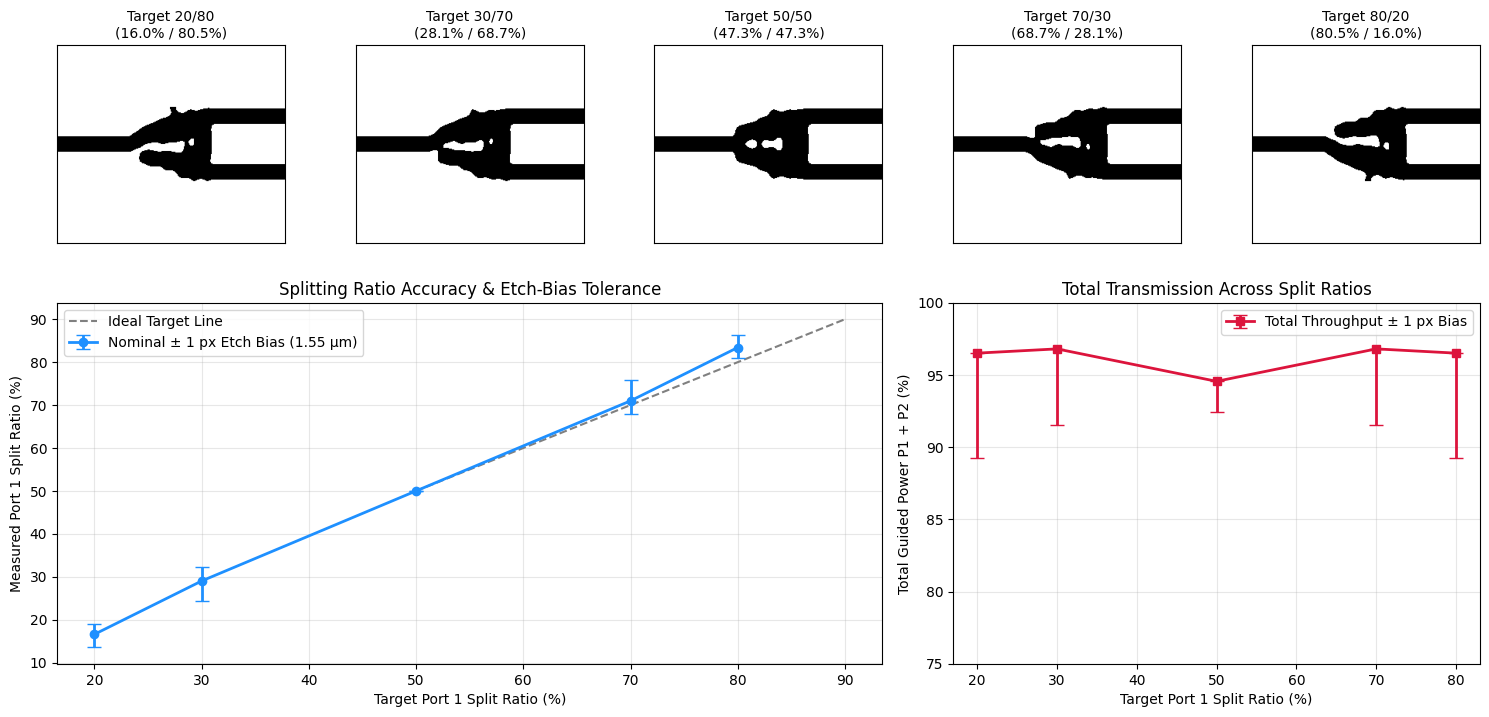

In [ ]:
fig = plt.figure(figsize=(15, 7.5))
gs = fig.add_gridspec(2, 5, height_ratios=[1.0, 1.15])

# Top row: Optimized binary silicon topologies for each split ratio
for idx, r in enumerate(ratios):
    ax = fig.add_subplot(gs[0, idx])
    eps_grid = sweep_results[r]["fit"]["eps_norm"]
    t1 = sweep_results[r]["fit"]["t1_fit"] * 100
    t2 = sweep_results[r]["fit"]["t2_fit"] * 100
    ax.imshow(eps_grid.T, cmap="Greys", origin="lower")
    ax.set_title(f"Target {r*100:.0f}/{(1-r)*100:.0f}\n({t1:.1f}% / {t2:.1f}%)", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

# Extract nominal (0 px) and ±1 px etch-bias bounds at λ = 1.55 μm (index 1)
targets_pct = np.array(ratios) * 100
nom_ratio = np.array([sweep_results[r]["rob"]["ratio"][1, 1] * 100 for r in ratios])
min_ratio = np.array([sweep_results[r]["rob"]["ratio"][1, :].min() * 100 for r in ratios])
max_ratio = np.array([sweep_results[r]["rob"]["ratio"][1, :].max() * 100 for r in ratios])

nom_tot = np.array([sweep_results[r]["rob"]["total"][1, 1] * 100 for r in ratios])
min_tot = np.array([sweep_results[r]["rob"]["total"][1, :].min() * 100 for r in ratios])
max_tot = np.array([sweep_results[r]["rob"]["total"][1, :].max() * 100 for r in ratios])

# Bottom-left: Achieved vs. Target Split Ratio with ±1 px bias bars
ax_r = fig.add_subplot(gs[1, :3])
ax_r.plot([50, 90], [50, 90], "--", color="gray", label="Ideal Target Line")
ax_r.errorbar(
    targets_pct, nom_ratio,
    yerr=[nom_ratio - min_ratio, max_ratio - nom_ratio],
    fmt="o-", lw=2, capsize=5, color="dodgerblue", label="Nominal ± 1 px Etch Bias (1.55 μm)"
)
ax_r.set_xlabel("Target Port 1 Split Ratio (%)")
ax_r.set_ylabel("Measured Port 1 Split Ratio (%)")
ax_r.set_title("Splitting Ratio Accuracy & Etch-Bias Tolerance")
ax_r.grid(True, alpha=0.3)
ax_r.legend()

# Bottom-right: Total Transmission (P1 + P2) across Split Ratios
ax_t = fig.add_subplot(gs[1, 3:])
ax_t.errorbar(
    targets_pct, nom_tot,
    yerr=[nom_tot - min_tot, max_tot - nom_tot],
    fmt="s-", lw=2, capsize=5, color="crimson", label="Total Throughput ± 1 px Bias"
)
ax_t.set_xlabel("Target Port 1 Split Ratio (%)")
ax_t.set_ylabel("Total Guided Power P1 + P2 (%)")
ax_t.set_ylim(75, 100)
ax_t.set_title("Total Transmission Across Split Ratios")
ax_t.grid(True, alpha=0.3)
ax_t.legend()

plt.tight_layout()
plt.show()